In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files
from pathlib import Path

file_path = Path("/content/Online Retail.xlsx")

if not file_path.exists():
    print("Please upload Online Retail.xlsx")
    uploaded = files.upload()
    file_path = Path(next(iter(uploaded)))

df = pd.read_excel(file_path, nrows=5000)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Dataset loaded successfully!")


Please upload Online Retail.xlsx


Saving Online Retail.xlsx to Online Retail.xlsx
Rows: 5000
Columns: 8
Dataset loaded successfully!


In [3]:

sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.upper().str.startswith("C"))
].copy()

sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

sales_df["SalesValue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print("Positive sales records:", len(sales_df))


Positive sales records: 4918


In [4]:

total_skus = sales_df["StockCode"].nunique()
total_quantity = sales_df["Quantity"].sum()
total_sales = sales_df["SalesValue"].sum()

print("Unique SKUs:", total_skus)
print("Quantity Sold:", total_quantity)
print("Sales Value: £", round(total_sales, 2))


Unique SKUs: 1579
Quantity Sold: 56340
Sales Value: £ 104055.57


,Quantity
StockCode,
84077,2976
84950,1842
21915,1549
85123A,761
84029E,686
21212,676
22616,656
84879,623
21137,613


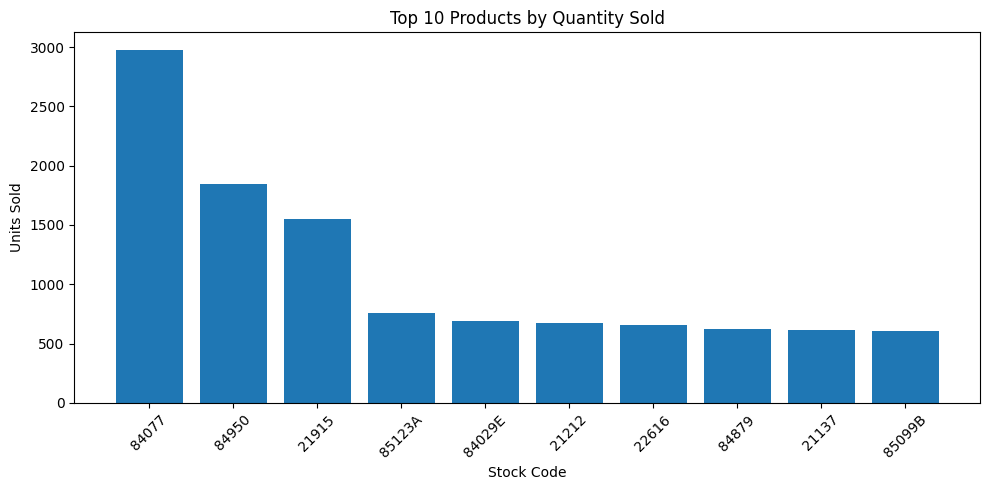

In [5]:

top_10_products = (
    sales_df.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_10_products)

plt.figure(figsize=(10, 5))

plt.bar(
    top_10_products.index.astype(str),
    top_10_products.values
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Stock Code")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("/content/top_10_products.png", dpi=300)
plt.show()


In [6]:

abc_df = (
    sales_df.groupby("StockCode", as_index=False)
    .agg(
        TotalQuantity=("Quantity", "sum"),
        TotalSalesValue=("SalesValue", "sum")
    )
)

abc_df = abc_df.sort_values(
    "TotalSalesValue", ascending=False
).reset_index(drop=True)

total_value = abc_df["TotalSalesValue"].sum()

abc_df["ValuePercent"] = (
    abc_df["TotalSalesValue"] / total_value * 100
)

abc_df["CumulativePercent"] = (
    abc_df["ValuePercent"].cumsum()
)

previous_percent = (
    abc_df["CumulativePercent"] -
    abc_df["ValuePercent"]
)

abc_df["ABC_Class"] = np.select(
    [
        previous_percent < 80,
        previous_percent < 95
    ],
    ["A", "B"],
    default="C"
)

abc_summary = (
    abc_df.groupby("ABC_Class")
    .agg(
        NumberOfSKUs=("StockCode", "count"),
        TotalSalesValue=("TotalSalesValue", "sum")
    )
    .reindex(["A", "B", "C"], fill_value=0)
)

abc_summary["ValueSharePercent"] = (
    abc_summary["TotalSalesValue"] /
    total_value * 100
)

display(abc_summary.round(2))


,NumberOfSKUs,TotalSalesValue,ValueSharePercent
ABC_Class,,,
A,361,83287.92,80.04
B,493,15575.16,14.97
C,725,5192.49,4.99


In [7]:

rng = np.random.default_rng(42)

start_date = sales_df["InvoiceDate"].min()
end_date = sales_df["InvoiceDate"].max()

observation_days = (
    end_date.normalize() -
    start_date.normalize()
).days + 1

inventory_df = abc_df[
    ["StockCode", "TotalQuantity",
     "TotalSalesValue", "ABC_Class"]
].copy()

inventory_df["AverageDailyDemand"] = (
    inventory_df["TotalQuantity"] /
    observation_days
)

simulated_coverage = rng.integers(
    2, 31, size=len(inventory_df)
)

inventory_df["StockOnHand"] = np.ceil(
    inventory_df["AverageDailyDemand"] *
    simulated_coverage
).astype(int)

inventory_df["LeadTimeDays"] = rng.integers(
    3, 15, size=len(inventory_df)
)

inventory_df["SafetyStock"] = np.ceil(
    inventory_df["AverageDailyDemand"] * 5
).astype(int)

print("Simulated inventory created!")
print("SKUs:", len(inventory_df))


Simulated inventory created!
SKUs: 1579


In [8]:

inventory_df["StockCoverageDays"] = (
    inventory_df["StockOnHand"] /
    inventory_df["AverageDailyDemand"].replace(0, np.nan)
)

inventory_df["ReorderPoint"] = np.ceil(
    inventory_df["AverageDailyDemand"] *
    inventory_df["LeadTimeDays"] +
    inventory_df["SafetyStock"]
).astype(int)

target_stock = np.ceil(
    inventory_df["AverageDailyDemand"] *
    (inventory_df["LeadTimeDays"] + 14) +
    inventory_df["SafetyStock"]
)

inventory_df["SuggestedOrderQty"] = np.maximum(
    0,
    target_stock - inventory_df["StockOnHand"]
).astype(int)

inventory_df["InventoryStatus"] = np.where(
    inventory_df["StockOnHand"] <=
    inventory_df["ReorderPoint"],
    "Reorder Required",
    "Sufficient Stock"
)

inventory_df["CoverageGapDays"] = (
    inventory_df["StockCoverageDays"] -
    inventory_df["LeadTimeDays"]
)

inventory_df["InventoryRiskLevel"] = np.select(
    [
        inventory_df["CoverageGapDays"].isna(),
        inventory_df["CoverageGapDays"] < -5,
        inventory_df["CoverageGapDays"] < 0,
        inventory_df["CoverageGapDays"] < 5
    ],
    ["Unknown", "Critical", "High", "Medium"],
    default="Low"
)

print("Inventory calculations completed!")

display(
    inventory_df["InventoryStatus"].value_counts()
)


Inventory calculations completed!


,count
InventoryStatus,
Sufficient Stock,896
Reorder Required,683


In [9]:

reorder_required = (
    inventory_df["InventoryStatus"]
    .eq("Reorder Required")
    .sum()
)

average_coverage = (
    inventory_df["StockCoverageDays"].mean()
)

a_class_reorder = len(inventory_df[
    (inventory_df["ABC_Class"] == "A") &
    (inventory_df["InventoryStatus"] == "Reorder Required")
])

critical_a = len(inventory_df[
    (inventory_df["ABC_Class"] == "A") &
    (inventory_df["InventoryRiskLevel"] == "Critical")
])

print("Total SKUs:", len(inventory_df))
print("Reorder Required:", reorder_required)
print("Average Coverage:", round(average_coverage, 2))
print("A-Class Reorder:", a_class_reorder)
print("Critical A-Class:", critical_a)


Total SKUs: 1579
Reorder Required: 683
Average Coverage: 16.21
A-Class Reorder: 157
Critical A-Class: 29


In [10]:

abc_df.to_csv(
    "/content/abc_analysis.csv",
    index=False
)

inventory_df.to_csv(
    "/content/inventory_planning.csv",
    index=False
)

print("CSV files created successfully!")


CSV files created successfully!


In [11]:

from google.colab import files

files.download("/content/abc_analysis.csv")
files.download("/content/inventory_planning.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>